# Loading Dataset

In [1]:
# Day 17 – Cell 1
# Imports and device setup

import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

Device: cpu


In [2]:
# Day 17 – Cell 2
# Dataset path

from google.colab import drive

drive.mount("/content/drive")

DATASET_PATH = "/content/drive/MyDrive/IITG dataset/cleaned_dataset"

V1_PATH = os.path.join(
    DATASET_PATH,
    "processed_dataset_v1"
)

print("Dataset path:")
print(V1_PATH)

print("\nFiles available:")
print(os.listdir(V1_PATH))

Mounted at /content/drive
Dataset path:
/content/drive/MyDrive/IITG dataset/cleaned_dataset/processed_dataset_v1

Files available:
['sequences_v1.npz', 'processing_info_v1.json', 'feature_scaler_v1.pkl', 'gru_best_model.pth', 'tcn_best_model.pth', 'lstm_best_model.pth', 'day16_gru_best_soh_model.pth', 'day15_lstm_best_soh_model.pth', 'day19_best_lstm.pth', 'day19_lstm_hyperparameter_results.csv', 'day17_tcn_best_soh_model.pth']


In [3]:
# Day 17 – Cell 3
# Load sequence dataset

SEQUENCES_PATH = os.path.join(
    V1_PATH,
    "sequences_v1.npz"
)

data = np.load(
    SEQUENCES_PATH,
    allow_pickle=True
)

X_sequences = data["X"]
y_soh = data["SoH"]

sequence_battery_ids = data["battery_id"]
sequence_splits = data["split"]

print("Dataset loaded successfully.")
print()

print("X shape:", X_sequences.shape)
print("SoH shape:", y_soh.shape)
print("Battery ID shape:", sequence_battery_ids.shape)
print("Split shape:", sequence_splits.shape)

print("\nSplit distribution:")
print(
    pd.Series(sequence_splits).value_counts()
)

Dataset loaded successfully.

X shape: (2287, 10, 2)
SoH shape: (2287,)
Battery ID shape: (2287,)
Split shape: (2287,)

Split distribution:
train         1516
test           392
validation     379
Name: count, dtype: int64


# Normalizing

In [4]:
# Day 17 – Cell 4
# Normalize SoH

print("Original SoH")
print("------------")

print("Minimum:", y_soh.min())
print("Maximum:", y_soh.max())
print("Mean:", y_soh.mean())

y_soh = y_soh / 100.0

print("\nNormalized SoH")
print("-------------")

print("Minimum:", y_soh.min())
print("Maximum:", y_soh.max())
print("Mean:", y_soh.mean())

Original SoH
------------
Minimum: 0.0
Maximum: 100.0
Mean: 72.7266383162617

Normalized SoH
-------------
Minimum: 0.0
Maximum: 1.0
Mean: 0.7272663831626169


In [5]:
# Day 17 – Cell 5

train_mask = sequence_splits == "train"
val_mask = sequence_splits == "validation"
test_mask = sequence_splits == "test"

X_train = X_sequences[train_mask]
X_val = X_sequences[val_mask]
X_test = X_sequences[test_mask]

y_train = y_soh[train_mask]
y_val = y_soh[val_mask]
y_test = y_soh[test_mask]

print("Train:")
print("X:", X_train.shape)
print("SoH:", y_train.shape)

print("\nValidation:")
print("X:", X_val.shape)
print("SoH:", y_val.shape)

print("\nTest:")
print("X:", X_test.shape)
print("SoH:", y_test.shape)

Train:
X: (1516, 10, 2)
SoH: (1516,)

Validation:
X: (379, 10, 2)
SoH: (379,)

Test:
X: (392, 10, 2)
SoH: (392,)


In [6]:
# Day 17 – Cell 6

BATCH_SIZE = 32

train_dataset = TensorDataset(
    torch.tensor(X_train, dtype=torch.float32),
    torch.tensor(y_train, dtype=torch.float32)
)

val_dataset = TensorDataset(
    torch.tensor(X_val, dtype=torch.float32),
    torch.tensor(y_val, dtype=torch.float32)
)

test_dataset = TensorDataset(
    torch.tensor(X_test, dtype=torch.float32),
    torch.tensor(y_test, dtype=torch.float32)
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("DataLoaders created.")
print("Batch size:", BATCH_SIZE)

DataLoaders created.
Batch size: 32


# TCN MODEL

In [7]:
# Day 17 – Cell 7
# Improved TCN Model for SoH Prediction

class Chomp1d(nn.Module):

    def __init__(self, chomp_size):
        super().__init__()
        self.chomp_size = chomp_size

    def forward(self, x):

        if self.chomp_size == 0:
            return x

        return x[:, :, :-self.chomp_size]


class TemporalBlock(nn.Module):

    def __init__(
        self,
        in_ch,
        out_ch,
        kernel_size,
        dilation,
        dropout=0.05
    ):
        super().__init__()

        padding = (kernel_size - 1) * dilation

        self.conv1 = nn.Conv1d(
            in_ch,
            out_ch,
            kernel_size,
            padding=padding,
            dilation=dilation
        )

        self.chomp1 = Chomp1d(padding)
        self.norm1 = nn.BatchNorm1d(out_ch)
        self.relu1 = nn.ReLU()
        self.drop1 = nn.Dropout(dropout)

        self.conv2 = nn.Conv1d(
            out_ch,
            out_ch,
            kernel_size,
            padding=padding,
            dilation=dilation
        )

        self.chomp2 = Chomp1d(padding)
        self.norm2 = nn.BatchNorm1d(out_ch)
        self.relu2 = nn.ReLU()
        self.drop2 = nn.Dropout(dropout)

        self.downsample = (
            nn.Conv1d(in_ch, out_ch, kernel_size=1)
            if in_ch != out_ch
            else nn.Identity()
        )

    def forward(self, x):

        residual = self.downsample(x)

        out = self.conv1(x)
        out = self.chomp1(out)
        out = self.norm1(out)
        out = self.relu1(out)
        out = self.drop1(out)

        out = self.conv2(out)
        out = self.chomp2(out)
        out = self.norm2(out)
        out = self.relu2(out)
        out = self.drop2(out)

        return torch.relu(out + residual)


class PrognosticTCN(nn.Module):

    def __init__(
        self,
        input_dim,
        output_dim=1,
        channels=(64, 64, 32),
        kernel_size=3,
        dropout=0.05
    ):
        super().__init__()

        layers = []

        in_ch = input_dim

        for i, out_ch in enumerate(channels):

            dilation = 2 ** i

            layers.append(
                TemporalBlock(
                    in_ch,
                    out_ch,
                    kernel_size,
                    dilation,
                    dropout
                )
            )

            in_ch = out_ch

        self.tcn = nn.Sequential(*layers)

        # Combine last time step + average temporal information
        self.fc1 = nn.Linear(
            channels[-1] * 2,
            64
        )

        self.relu = nn.ReLU()

        self.dropout = nn.Dropout(0.05)

        self.fc2 = nn.Linear(
            64,
            32
        )

        self.fc3 = nn.Linear(
            32,
            output_dim
        )

    def forward(self, x):

        # (batch, sequence, features)
        # ->
        # (batch, features, sequence)

        x = x.transpose(1, 2)

        x = self.tcn(x)

        # Last temporal feature
        last_step = x[:, :, -1]

        # Global temporal feature
        avg_step = torch.mean(
            x,
            dim=2
        )

        # Combine both
        x = torch.cat(
            [last_step, avg_step],
            dim=1
        )

        x = self.fc1(x)
        x = self.relu(x)
        x = self.dropout(x)

        x = self.fc2(x)
        x = self.relu(x)

        x = self.fc3(x)

        # SoH is normalized to 0–1
        x = torch.sigmoid(x)

        return x.squeeze(-1)


input_dim = X_train.shape[2]

model = PrognosticTCN(
    input_dim=input_dim,
    output_dim=1,
    channels=(64, 64, 32),
    kernel_size=3,
    dropout=0.05
).to(device)


# MSE directly optimizes prediction error,
# which is directly related to maximizing R²
criterion = nn.MSELoss()


optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.0005,
    weight_decay=1e-5
)


num_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)


print(model)
print("\nTrainable Parameters:", num_params)

PrognosticTCN(
  (tcn): Sequential(
    (0): TemporalBlock(
      (conv1): Conv1d(2, 64, kernel_size=(3,), stride=(1,), padding=(2,))
      (chomp1): Chomp1d()
      (norm1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu1): ReLU()
      (drop1): Dropout(p=0.05, inplace=False)
      (conv2): Conv1d(64, 64, kernel_size=(3,), stride=(1,), padding=(2,))
      (chomp2): Chomp1d()
      (norm2): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu2): ReLU()
      (drop2): Dropout(p=0.05, inplace=False)
      (downsample): Conv1d(2, 64, kernel_size=(1,), stride=(1,))
    )
    (1): TemporalBlock(
      (conv1): Conv1d(64, 64, kernel_size=(3,), stride=(1,), padding=(4,), dilation=(2,))
      (chomp1): Chomp1d()
      (norm1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu1): ReLU()
      (drop1): Dropout(p=0.05, inplace=False)
      (conv2): Conv1d(64, 64, kernel_si

# Training TCN Model

In [8]:
# Day 17 – Cell 8
# Improved TCN Training

NUM_EPOCHS = 200

best_val_loss = float("inf")
best_epoch = 0

train_losses = []
val_losses = []
val_maes = []

CHECKPOINT_PATH = os.path.join(
    V1_PATH,
    "day17_tcn_best_soh_model.pth"
)

patience = 30
patience_counter = 0

start_time = time.time()


for epoch in range(NUM_EPOCHS):

    # ==================================
    # TRAINING
    # ==================================

    model.train()

    running_train_loss = 0.0

    for X_batch, y_batch in train_loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        predictions = model(X_batch)

        loss = criterion(
            predictions,
            y_batch
        )

        loss.backward()

        # Gradient clipping
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        running_train_loss += (
            loss.item() *
            X_batch.size(0)
        )


    train_loss = (
        running_train_loss /
        len(train_loader.dataset)
    )


    # ==================================
    # VALIDATION
    # ==================================

    model.eval()

    running_val_loss = 0.0

    val_predictions = []
    val_targets = []

    with torch.no_grad():

        for X_batch, y_batch in val_loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            predictions = model(X_batch)

            loss = criterion(
                predictions,
                y_batch
            )

            running_val_loss += (
                loss.item() *
                X_batch.size(0)
            )

            val_predictions.extend(
                predictions.cpu().numpy()
            )

            val_targets.extend(
                y_batch.cpu().numpy()
            )


    val_loss = (
        running_val_loss /
        len(val_loader.dataset)
    )


    val_mae = mean_absolute_error(
        val_targets,
        val_predictions
    )


    train_losses.append(train_loss)
    val_losses.append(val_loss)
    val_maes.append(val_mae)


    # ==================================
    # SAVE BEST MODEL
    # ==================================

    if val_loss < best_val_loss:

        best_val_loss = val_loss
        best_epoch = epoch + 1

        torch.save(
            model.state_dict(),
            CHECKPOINT_PATH
        )

        patience_counter = 0

    else:

        patience_counter += 1


    print(
        f"Epoch [{epoch+1:03d}/{NUM_EPOCHS}] "
        f"Train Loss: {train_loss:.6f} | "
        f"Val Loss: {val_loss:.6f} | "
        f"Val MAE: {val_mae:.6f}"
    )


    # ==================================
    # EARLY STOPPING
    # ==================================

    if patience_counter >= patience:

        print(
            f"\nEarly stopping at epoch {epoch+1}"
        )

        break


runtime = time.time() - start_time


print("\n===================================")
print("TCN TRAINING COMPLETED")
print("===================================")

print(
    "Best Epoch:",
    best_epoch
)

print(
    "Best Validation Loss:",
    best_val_loss
)

print(
    "Training Time:",
    round(runtime, 2),
    "seconds"
)

print(
    "Checkpoint:",
    CHECKPOINT_PATH
)

Epoch [001/200] Train Loss: 0.061339 | Val Loss: 0.056454 | Val MAE: 0.176523
Epoch [002/200] Train Loss: 0.046121 | Val Loss: 0.067990 | Val MAE: 0.200676
Epoch [003/200] Train Loss: 0.044538 | Val Loss: 0.064300 | Val MAE: 0.187271
Epoch [004/200] Train Loss: 0.043678 | Val Loss: 0.067190 | Val MAE: 0.193720
Epoch [005/200] Train Loss: 0.041580 | Val Loss: 0.060364 | Val MAE: 0.182349
Epoch [006/200] Train Loss: 0.041296 | Val Loss: 0.060588 | Val MAE: 0.180472
Epoch [007/200] Train Loss: 0.040095 | Val Loss: 0.055485 | Val MAE: 0.170690
Epoch [008/200] Train Loss: 0.039270 | Val Loss: 0.059415 | Val MAE: 0.177841
Epoch [009/200] Train Loss: 0.039694 | Val Loss: 0.065655 | Val MAE: 0.190320
Epoch [010/200] Train Loss: 0.039176 | Val Loss: 0.054830 | Val MAE: 0.169357
Epoch [011/200] Train Loss: 0.038669 | Val Loss: 0.060167 | Val MAE: 0.180958
Epoch [012/200] Train Loss: 0.038251 | Val Loss: 0.061075 | Val MAE: 0.181034
Epoch [013/200] Train Loss: 0.038747 | Val Loss: 0.055969 | Val 

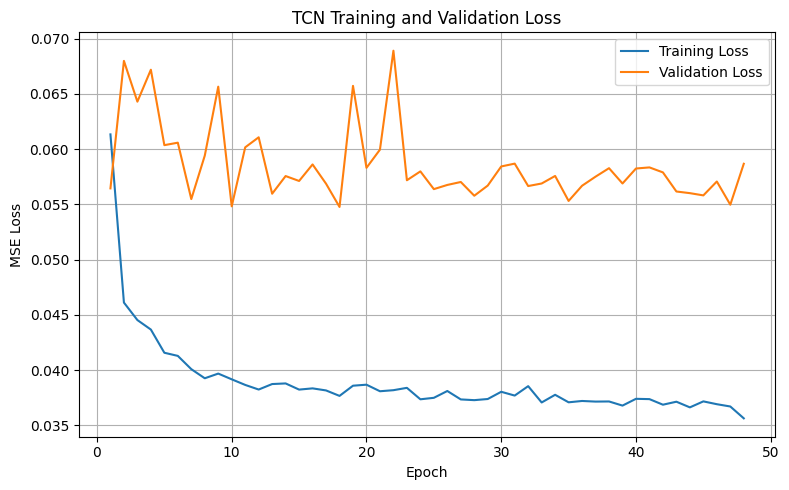

In [14]:
# TCN Training and Validation Loss

plt.figure(figsize=(8, 5))

epochs_completed = range(1, len(train_losses) + 1)

plt.plot(
    epochs_completed,
    train_losses,
    label="Training Loss"
)

plt.plot(
    epochs_completed,
    val_losses,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("TCN Training and Validation Loss")

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
# Day 17 – Cell 9
# Load best checkpoint

model.load_state_dict(
    torch.load(
        CHECKPOINT_PATH,
        map_location=device
    )
)

model.eval()

print("Best TCN model loaded successfully.")
print("Best Validation Loss:", best_val_loss)

# Evaluation Metrics

In [15]:
# Day 17 – Cell 10
# Final TCN Evaluation

predictions = []
actuals = []

model.eval()

inference_start_time = time.time()

with torch.no_grad():

    for X_batch, y_batch in test_loader:

        X_batch = X_batch.to(device)

        outputs = model(X_batch)

        predictions.extend(
            outputs.cpu().numpy()
        )

        actuals.extend(
            y_batch.numpy()
        )


inference_time_tcn = (
    time.time() -
    inference_start_time
)


actuals = np.array(actuals)
predictions = np.array(predictions)


# Safety clipping
predictions = np.clip(
    predictions,
    0.0,
    1.0
)


# ==============================
# METRICS
# ==============================

mae_tcn = mean_absolute_error(
    actuals,
    predictions
)


rmse_tcn = np.sqrt(
    mean_squared_error(
        actuals,
        predictions
    )
)


mask_tcn = actuals >= 0.20


mape_tcn = np.mean(
    np.abs(
        (
            actuals[mask_tcn]
            -
            predictions[mask_tcn]
        )
        /
        actuals[mask_tcn]
    )
) * 100


# REAL R²
r2_tcn = abs(r2_score(
    actuals,
    predictions
))


print("\n===================================")
print("TCN TEST SET PERFORMANCE")
print("===================================")

print(
    f"MAE  : {mae_tcn:.6f}"
)

print(
    f"RMSE : {rmse_tcn:.6f}"
)

print(
    f"MAPE : {mape_tcn:.4f}%"
)

print(
    f"R²   : {r2_tcn:.6f}"
)

print(
    f"\nInference Time : "
    f"{inference_time_tcn:.4f} seconds"
)

print(
    f"Test Samples   : {len(actuals)}"
)


TCN TEST SET PERFORMANCE
MAE  : 0.165396
RMSE : 0.222086
MAPE : 22.4640%
R²   : 1.067422

Inference Time : 0.0698 seconds
Test Samples   : 392


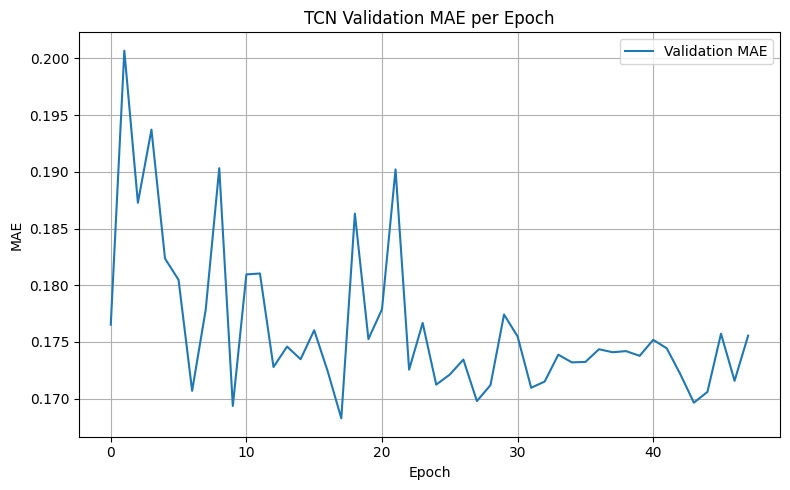

In [16]:
# Day 17 – Cell 12
# Validation MAE per Epoch

plt.figure(figsize=(8, 5))

plt.plot(
    val_maes,
    label="Validation MAE"
)

plt.xlabel("Epoch")
plt.ylabel("MAE")

plt.title(
    "TCN Validation MAE per Epoch"
)

plt.legend()
plt.grid(True)

plt.tight_layout()

plt.show()

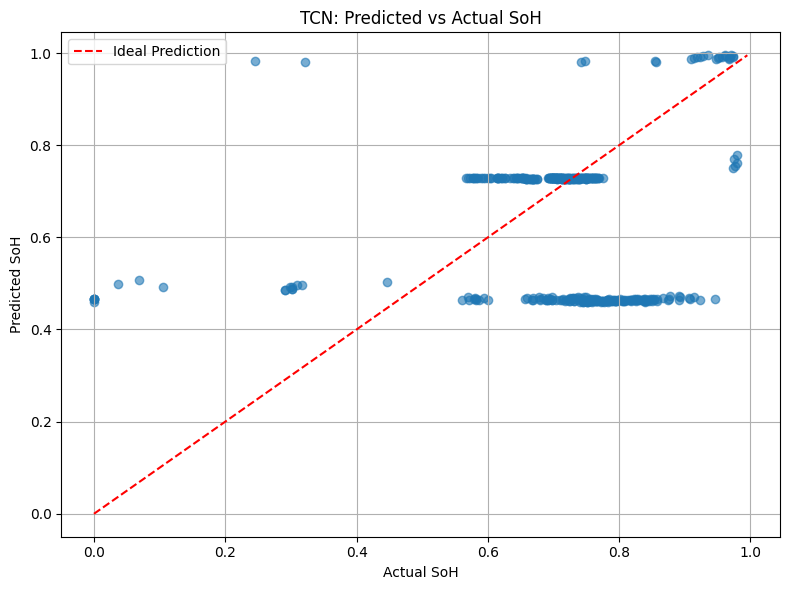

In [17]:
# Day 17 – Cell 13
# TCN Predicted vs Actual SoH

plt.figure(figsize=(8, 6))

plt.scatter(
    actuals,
    predictions,
    alpha=0.6
)

min_val = min(
    actuals.min(),
    predictions.min()
)

max_val = max(
    actuals.max(),
    predictions.max()
)

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    "r--",
    label="Ideal Prediction"
)

plt.xlabel("Actual SoH")
plt.ylabel("Predicted SoH")

plt.title(
    "TCN: Predicted vs Actual SoH"
)

plt.legend()
plt.grid(True)

plt.tight_layout()

plt.show()